# Visual action verification

## What you will build

**Recipe 88 · Level 3 (Intermediate) · Multiframe `Noul`**

Build a verifier for a simulated browser action: did opening a report dialog or saving a setting produce the requested visible state? A [Noul](../../docs/glossary.md#noul) is a typed probability that one proposition is true. Two independent propositions inspect the final screenshot and the initial screenshot; Python combines them into an outcome and a simulated handoff.

The input is an explicitly ordered sequence of timestamped PNG still images. There is no native video input, video decoding, browser control, or real settings change. A successful verification means the requested state is visible after an action whose timestamp Python supplied; screenshots alone cannot establish causation or persistence on a server. Images and replay answers are written for this recipe, so every offline metric is a pipeline check, not measured Jev behavior.

Image input is experimental, enabled explicitly, and this notebook requests pinned model `jev-1.14.0` for a live run. See [S09: Images](https://docs.typesafe.ai/images) and [S11: Models](https://docs.typesafe.ai/models).

Sources:

- S02: [Primitives](https://docs.typesafe.ai/primitives)
- S03: [Confidence](https://docs.typesafe.ai/confidence)
- S09: [Images](https://docs.typesafe.ai/images)
- S11: [Models](https://docs.typesafe.ai/models)
- S12: [Jev 1.14 release](https://typesafe.ai/blog/jev-1-14)


## Setup and run mode

Run from this recipe folder. The default backend replays [synthetic fixtures](../../docs/glossary.md#fixture); it needs neither a key nor a network. `images=True` is the explicit experimental image opt-in for the live backend, while replay uses the same state, questions, and content-addressed assets.

The sample has 11 validation examples, 11 held-out test examples, and two unscored demonstrations. Four malformed sequences are rejected before inference, leaving 20 requests. Each valid sequence batches its two independent questions into one call. Live setup and budgets are explained in [offline and live](../../docs/offline-and-live.md); the default budget of 25 accommodates these 20 attempts only when retries do not consume the remainder.

In [1]:
from pathlib import Path

from IPython.display import display
from matplotlib.figure import Figure
from PIL import Image

from jev_cookbook import get_backend, load_helpers
from jev_cookbook.evaluation import accuracy, evaluate_outcomes
from jev_cookbook.fixtures import load_inputs, load_labels, responses_path, select_split
from jev_cookbook.simulation import ActionLog, ReviewQueue
from jev_cookbook.style import apply_style, run_header, show_answer
from jev_cookbook.vision import run_record

RECIPE = Path.cwd()
helpers = load_helpers()
examples = load_inputs()
labels = load_labels()
validation = select_split(examples, "validation")
test = select_split(examples, "test")
demos = select_split(examples, "demo")
backend = get_backend(fixtures=responses_path(), images=True, model="jev-1.14.0")
apply_style()
run_header(
    88, "Visual action verification", backend=backend, n_examples=len(validation) + len(test)
)
check = " (a pipeline check, not a Jev result)" if backend.mode == "synthetic" else ""
selection = " (a selection step, not a reported result)"
reportable = backend.mode != "live"

Recipe 88: Visual action verification
Mode: offline replay of synthetic fixtures, pipeline check on a fixture sample of 22 examples
Metrics in this run are checks that the pipeline works. They are not Jev results.


## The state

Python owns the intent, the action timestamp, capture order, and file checks. A valid sequence contains one `before` frame and at least one `after` frame. Timestamps are integer milliseconds on the same invented monotonic clock: strictly increasing, with the action strictly between the first two captures. Python rejects reversal; sorting an accidentally reversed list would hide a capture defect.

`build_request` reads PNG bytes through `image_asset` and places opaque content references in [state](../../docs/glossary.md#state). The separate `assets` mapping supplies the raw images. Filenames, example IDs, split names, gold labels, rendering scene names, and synthetic probabilities never enter inference state. The [replay key](../../docs/glossary.md#replay-key) includes image contents and ordered timestamp metadata, so replacing a screenshot cannot silently reuse its old answer.

The panels below are the actual first demonstration frames. The settings cases with a delay include an intermediate `Saving...` frame; verification concerns the final captured frame, not an assumed future result.

Click Export report.
Simulated action timestamp: 1000 ms
Desired postcondition: The Export report dialog is open.
Ordered frame timestamps: [900, 1500]


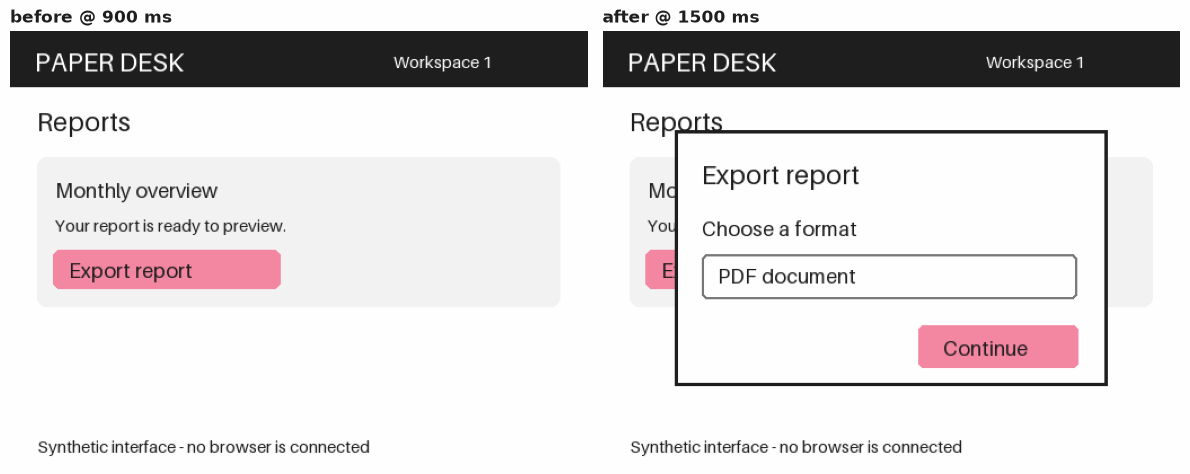

In [2]:
def show_sequence(example):
    frames = example.fields["frames"]
    fig = Figure(figsize=(6 * len(frames), 4.8))
    for index, frame in enumerate(frames):
        ax = fig.add_subplot(1, len(frames), index + 1)
        with Image.open(RECIPE / frame["asset"]) as image:
            ax.imshow(image.copy())
        ax.set_title(f"{frame['phase']} @ {frame['timestamp_ms']} ms")
        ax.axis("off")
    fig.tight_layout()
    print(helpers.INTENTS[example.fields["intent"]]["action"])
    print(f"Simulated action timestamp: {example.fields['action_timestamp_ms']} ms")
    display(fig)


show_sequence(demos[0])
state, questions, assets = helpers.build_request(demos[0].fields, RECIPE)
print("Desired postcondition:", state["desired_postcondition"])
print("Ordered frame timestamps:", [f["timestamp_ms"] for f in state["frames_in_capture_order"]])

## The questions

The desired postcondition is fixed by Python: either “The Export report dialog is open” or “The notifications panel displays the saved-state confirmation ‘Saved: enabled’.” Each `postcondition` Noul asks only whether that one visible state appears in the final frame. Enabling a toggle with an `Unsaved changes` notice does not satisfy the saved-state proposition.

The independent `initially_absent` Noul asks whether that same state was absent in the first frame. This prevents an already-open dialog from becoming evidence of a successful new opening. Both questions use the same screenshots and go in one request, as described in [S02: Primitives](https://docs.typesafe.ai/primitives). A before/after pair can support a visible transition; it cannot prove that a click caused it.

[Noul certainty](../../docs/glossary.md#confidence) is derived by Python as `abs(2*p - 1)`, following [S03: Confidence](https://docs.typesafe.ai/confidence). It is not an extra field returned by Noul. The smaller of the two certainties governs the compound policy.

In [3]:
for name, question in questions.items():
    print(name + ":", question.instructions)

postcondition: In the final after screenshot, this statement is true: The Export report dialog is open.
initially_absent: In the first before screenshot, the following postcondition is absent: The Export report dialog is open.


## One answer up close

A replay answer is a typed stored response to the exact request. Show both probabilities and their [provenance](../../docs/glossary.md#provenance) before aggregating anything. Demonstrations are never scored, and each answer is reused instead of repeating a call.

In [4]:
demo_results = helpers.collect(demos, backend, RECIPE)
for name, answer in demo_results[demos[0].id].answers.items():
    print(name)
    show_answer(answer)

postcondition
Noul: 0.98 probability of yes (0 is no, 1 is yes)
Provenance: synthetic
initially_absent
Noul: 0.97 probability of yes (0 is no, 1 is yes)
Provenance: synthetic


A second demonstration changes a help banner while leaving the dialog closed. The independent baseline treats at least 1% changed RGB pixels as success. Its threshold is fixed here as a simple engineering heuristic; it uses neither gold labels nor model answers. This deliberately weak rule cannot connect a visible change to an action intent.

Click Export report.
Simulated action timestamp: 1000 ms
postcondition
Noul: 0.04 probability of yes (0 is no, 1 is yes)
Provenance: synthetic
initially_absent
Noul: 0.98 probability of yes (0 is no, 1 is yes)
Provenance: synthetic
Pixel-change baseline: success
The requested dialog is still closed; the changed banner is unrelated.


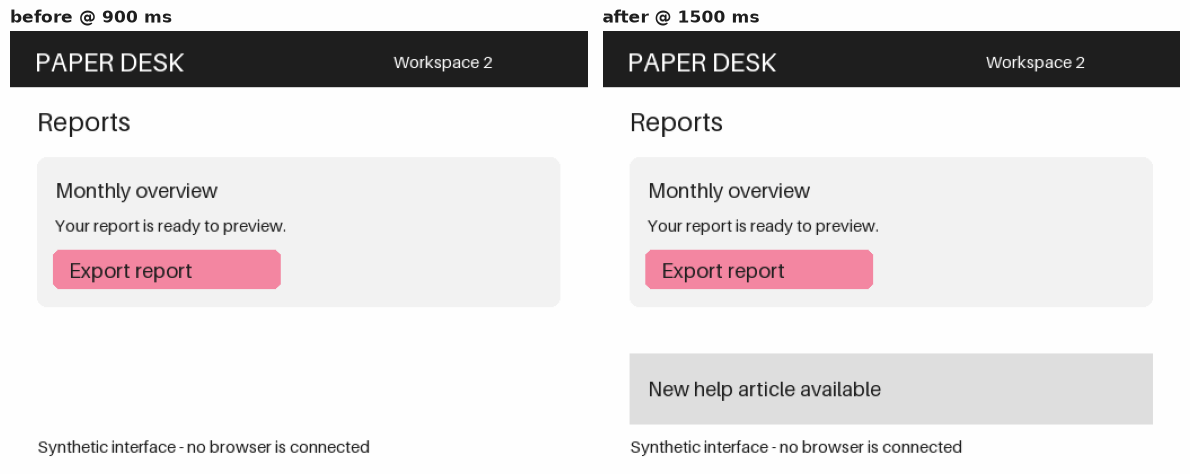

In [5]:
show_sequence(demos[1])
for name, answer in demo_results[demos[1].id].answers.items():
    print(name)
    show_answer(answer)
print("Pixel-change baseline:", helpers.pixel_baseline(demos[1].fields, RECIPE))
print("The requested dialog is still closed; the changed banner is unrelated.")

## Python's part

Python first validates image decoding, equal dimensions, frame roles, and timestamp order. Invalid evidence goes to the [review queue](../../docs/glossary.md#review) without a model request. With valid evidence, an unestablished initial absence also goes to review. The remaining cases must pass an inclusive [confidence gate](../../docs/glossary.md#confidence-gate) on **both** answers. A certain false final postcondition is the complete answer `not_observed`; it records no action and is gated just like success. A weak answer goes to review.

Only a verified transition records `simulated handoff accepted` in `ActionLog`, whose `executed` field is always false. A review entry asks a person to inspect evidence; it never retries a click or saves a setting.

Select the certainty gate using the [validation split](../../docs/fixtures.md#splits) only. The objective is the lowest observed threshold at which all eligible validation outcomes are correct (`target_accuracy=1.0`), not a guarantee on future data. Eligible means a valid request and a positive `initially_absent` answer; unconditional review cases have no invented certainty. Freeze the resulting gate before inspecting test answers. The authored low-certainty errors make the selection step visible.

In [6]:
validation_results = helpers.collect(validation, backend, RECIPE)
frozen_gate = helpers.freeze_gate(validation, validation_results, labels)
eligible = [
    e
    for e in validation
    if validation_results[e.id] is not None
    and validation_results[e.id]["initially_absent"].noul >= 0.5
]
print(
    f"Validation N={len(validation)}, eligible N={len(eligible)}; "
    f"frozen certainty gate={frozen_gate:.3f}{selection}{check}"
)

demo_actions, demo_queue = ActionLog(), ReviewQueue()
for example in demos:
    outcome = helpers.classify(
        example,
        demo_results[example.id],
        frozen_gate,
        RECIPE,
        actions=demo_actions,
        queue=demo_queue,
    )
    print(example.id, outcome.outcome, outcome.reason)
print("Simulated action entries:", demo_actions.to_dicts())
invalid_example = next(e for e in validation if e.id == "v09")
invalid_outcome = helpers.classify(
    invalid_example, None, frozen_gate, RECIPE, actions=demo_actions, queue=demo_queue
)
print("Reversed-frame outcome:", invalid_outcome.outcome, invalid_outcome.reason)
print("Review entries:", demo_queue.to_dicts())

Validation N=11, eligible N=8; frozen certainty gate=0.860 (a selection step, not a reported result) (a pipeline check, not a Jev result)
d01 success requested visible transition verified
d02 not_observed requested postcondition not observed
Simulated action entries: [{'seq': 0, 'kind': 'simulated handoff accepted', 'payload': {'example_id': 'd01', 'intent': 'open_export'}, 'step': None, 'answer': {'model': 'synthetic', 'usage': {'input_tokens': None, 'output_tokens': None}, 'answers': {'postcondition': {'type': 'noul', 'noul': 0.98, 'provenance': {'source': 'synthetic', 'model': None, 'date': None}}, 'initially_absent': {'type': 'noul', 'noul': 0.97, 'provenance': {'source': 'synthetic', 'model': None, 'date': None}}}}, 'rule': 'valid ordered frames, initially absent, postcondition true, certainty gate', 'executed': False}]
Reversed-frame outcome: review frames are not in strict chronological order
Review entries: [{'id': 0, 'item': {'example_id': 'v09'}, 'reason': 'frames are not in 

## Evaluation

Now use the frozen policy on test once. [Gold labels](../../docs/glossary.md#gold-label) describe the expected event outcome: `success`, `not_observed`, or `review`. A loading-only final frame has gold `not_observed`: the requested state has not appeared at the capture deadline, regardless of what happens later. Its authored uncertain answer still goes to review and counts as a missed negative decision. An obscured target region has gold `review` because the underlying postcondition cannot be established; a confident answer there could still be a semantic error. A complete loading-then-saved sequence can establish success. Missing/reversed evidence and an already-satisfied initial state also require review. Labels remain outside model state.

Report event/workflow [accuracy](../../docs/glossary.md#accuracy) on all 11 test sequences, and actual answered [coverage](../../docs/glossary.md#coverage), accepted accuracy, and abstention from `evaluate_outcomes`. It consumes real dispositions, including hard review branches. Review is not answered coverage, even when the gold outcome is review. Success [precision](../../docs/glossary.md#precision) and [recall](../../docs/glossary.md#recall) treat an accepted handoff as the detected event. Their denominators are printed explicitly; [risk](../../docs/glossary.md#risk) is error rate among answered cases.

Compare the pixel-change baseline on the same 11 cases with the same structural checks. It has no semantic or uncertainty signal. This comparison describes pipeline behavior over tiny invented examples, not model quality. The saved-toggle trap includes an intentionally confident wrong synthetic response to demonstrate that gating cannot eliminate every semantic error.

In [7]:
test_results = helpers.collect(test, backend, RECIPE)
actions, queue = ActionLog(), ReviewQueue()
outcomes = [
    helpers.classify(e, test_results[e.id], frozen_gate, RECIPE, actions=actions, queue=queue)
    for e in test
]
gold = [labels[e.id] for e in test]
predicted = [o.outcome for o in outcomes]
accepted = [outcome != helpers.REVIEW for outcome in predicted]
correct = [prediction == target for prediction, target in zip(predicted, gold, strict=True)]
selective = evaluate_outcomes(accepted, correct)
baseline = [helpers.pixel_baseline(e.fields, RECIPE) for e in test]
true_successes = sum(
    p == "success" and g == "success" for p, g in zip(predicted, gold, strict=True)
)
predicted_successes = sum(p == "success" for p in predicted)
gold_successes = sum(g == "success" for g in gold)

if reportable:
    print(f"Test N={len(test)}; event/workflow accuracy={accuracy(gold, predicted):.3f}{check}")
    print(
        f"Test N={len(test)}; answered={selective.n_answered}, coverage={selective.coverage:.3f}, "
        f"abstention={1 - selective.coverage:.3f}{check}"
    )
    print(
        f"Answered N={selective.n_answered}; accuracy={selective.accuracy:.3f}, "
        f"risk={selective.risk:.3f}{check}"
    )
    print(
        f"Success precision={true_successes}/{predicted_successes}; "
        f"success recall={true_successes}/{gold_successes}{check}"
    )
    print(
        f"False accepted handoffs={predicted_successes - true_successes}/{predicted_successes}{check}"
    )
    print(
        f"Pixel baseline N={len(test)}; event/workflow accuracy={accuracy(gold, baseline):.3f}{check}"
    )
    print("id   gold           policy         pixel baseline")
    for example, target, prediction, pixel in zip(test, gold, predicted, baseline, strict=True):
        print(f"{example.id:4} {target:14} {prediction:14} {pixel}")
else:
    print(
        "Live judgments collected; quality results are not reportable until recorded and replayed."
    )

Test N=11; event/workflow accuracy=0.727 (a pipeline check, not a Jev result)
Test N=11; answered=5, coverage=0.455, abstention=0.545 (a pipeline check, not a Jev result)
Answered N=5; accuracy=0.800, risk=0.200 (a pipeline check, not a Jev result)
Success precision=2/3; success recall=2/3 (a pipeline check, not a Jev result)
False accepted handoffs=1/3 (a pipeline check, not a Jev result)
Pixel baseline N=11; event/workflow accuracy=0.545 (a pipeline check, not a Jev result)
id   gold           policy         pixel baseline
t01  success        success        success
t02  success        success        success
t03  not_observed   not_observed   not_observed
t04  not_observed   not_observed   success
t05  success        review         success
t06  not_observed   review         success
t07  review         review         success
t08  review         review         review
t09  review         review         review
t10  review         review         not_observed
t11  not_observed   success    

The row table exposes two different failure modes. A banner can fool pixel differencing while the independent postcondition remains false. Conversely, the synthetic answer for the enabled-but-unsaved toggle can pass a certainty gate despite being wrong. The pictures and authored probabilities explain those cases; neither is an observed Jev error.

Test artwork uses a second layout and distinct workspace text, but shares the drawing program and action family with validation. It is held out from threshold selection, not representative independent application data. A later live study should split by application/session and include animation, capture failures, asynchronous state changes, and independent save verification.

## What was and was not measured

The cell below states mode and N in every branch, plus returned model and capture date for recorded results. Synthetic responses have no model inference latency, input tokens, or cost; these values stay `None`. The example request record shows how absent measurements stay absent rather than becoming zero. Image timestamps are invented capture metadata, not measured inference latency.

Policy numbers are synthetic pipeline checks in this committed notebook. For recorded replay, they describe only the captured held-out sample with the returned versioned model and dates. An interactive live run must be deliberately recorded before its quality numbers are reportable. No browser action, external setting change, throughput benchmark, or monetary measurement was performed here.

In [8]:
all_results = {**demo_results, **validation_results, **test_results}
returned = [result for result in all_results.values() if result is not None]
print(
    f"Mode: {backend.mode}; validation N={len(validation)}, test N={len(test)}, "
    f"demo N={len(demos)}; visual requests N={len(returned)}"
)
if backend.mode == "synthetic":
    print("Not measured live: a pipeline check, not a Jev result.")
    print(f"N: validation={len(validation)}, test={len(test)}, demo={len(demos)}")
elif backend.mode == "recorded":
    print("Returned model:", backend.model)
    print("Capture dates:", backend.recorded_dates)
    print(f"Reported results describe only held-out test N={len(test)}.")
else:
    print("Returned model(s):", sorted({result.model for result in returned}))
    print("Record answers before reporting held-out quality results.")
print("One request's measurement availability (N=1):")
print(run_record(returned[0], mode=backend.mode))

Mode: synthetic; validation N=11, test N=11, demo N=2; visual requests N=20
Not measured live: a pipeline check, not a Jev result.
N: validation=11, test=11, demo=2
One request's measurement availability (N=1):
{'model': None, 'input_tokens': None, 'output_tokens': None, 'latency_seconds': None, 'cost_usd': None, 'mode': 'synthetic'}


## Next steps

Try a delayed sequence with three after frames while retaining Python's order checks. Add an action only by supplying one explicit visible postcondition, authoring new validation/test examples, and regenerating replay keys. To study application behavior, capture consented synthetic-account screens and record returned model, date, and request measurements; preserve missing telemetry as unknown.

Compare the visual-evidence handoff with [29 — Tool outcome verification](../29-tool-outcome-verification/), which verifies structured tool evidence, and [25 — Change evidence review](../25-change-evidence-review/), which asks whether change claims have support. Their notebooks are already published. The [fixture contract](../../docs/fixtures.md) explains regeneration and protection of recorded responses.

Sources: [S02 — Primitives](https://docs.typesafe.ai/primitives), [S03 — Confidence](https://docs.typesafe.ai/confidence), [S09 — Images](https://docs.typesafe.ai/images), [S11 — Models](https://docs.typesafe.ai/models), [S12 — Jev 1.14 release](https://typesafe.ai/blog/jev-1-14).